<a href="https://colab.research.google.com/github/MelB18/EasyQuanten/blob/main/LiebRobinsonSchranke.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Wenn Raum und Zeit selbst aus einem Netzwerk von Quanten-Korrelationen hervorgehen, definiert die Lichtgeschwindigkeit, wie schnell sich Verschränkung maximal von einem Teilsystem zum nächsten ausbreiten können. In der Vielteilchen-Quantenphysik nennt man dieses natürliche Tempolimit die Lieb-Robinson-Schranke – sie erzeugt einen effektiven „Lichtkegel“, obwohl im Hintergrund gar keine relativistische Raumzeit einprogrammiert wurde.

Wenn Raum und Zeit selbst aus einem Netzwerk von Quanten-Korrelationen hervorgehen, definiert die Lichtgeschwindigkeit, wie schnell sich Verschränkung maximal von einem Teilsystem zum nächsten ausbreiten können. In der Vielteilchen-Quantenphysik nennt man dieses natürliche Tempolimit die Lieb-Robinson-Schranke – sie erzeugt einen effektiven „Lichtkegel“, obwohl im Hintergrund gar keine relativistische Raumzeit einprogrammiert wurde.

In [1]:
!pip install 'qiskit[visualization]'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 29.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 41.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [qiskit]


In [32]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit.library import HamiltonianGate
from qiskit.quantum_info import SparsePauliOp, Statevector

# --- 1. SYSTEM-SETUP: 1D-QUBIT-KETTE ---
n_qubits = 7                 # Kette von Qubit 0 (links) bis Qubit 6 (rechts)
J = 1.0                      # Kopplungsstärke zwischen direkten Nachbarn
h = 0.5                      # Lokales Magnetfeld

In [33]:
# Hamilton-Operator mit Nächste-Nachbar-Wechselwirkung (XX + YY-Kopplung)
pauli_terms = []
for i in range(n_qubits - 1):
    # Baut Strings wie "IIIIIXX" für Nachbarn i und i+1
    # (Qiskit-Reihenfolge: Qubit 0 steht ganz rechts!)
    xx_str = ["I"] * n_qubits
    yy_str = ["I"] * n_qubits
    xx_str[n_qubits - 1 - i] = "X"
    xx_str[n_qubits - 2 - i] = "X"
    yy_str[n_qubits - 1 - i] = "Y"
    yy_str[n_qubits - 2 - i] = "Y"

    pauli_terms.append(("".join(xx_str), J))
    pauli_terms.append(("".join(yy_str), J))

print(pauli_terms)

[('IIIIIXX', 1.0), ('IIIIIYY', 1.0), ('IIIIXXI', 1.0), ('IIIIYYI', 1.0), ('IIIXXII', 1.0), ('IIIYYII', 1.0), ('IIXXIII', 1.0), ('IIYYIII', 1.0), ('IXXIIII', 1.0), ('IYYIIII', 1.0), ('XXIIIII', 1.0), ('YYIIIII', 1.0)]


In [34]:
for i in range(n_qubits):
      z_str = ["I"] * n_qubits
      z_str[n_qubits - 1 - i] = "Z"
      pauli_terms.append(("".join(z_str), h))
print(pauli_terms)

[('IIIIIXX', 1.0), ('IIIIIYY', 1.0), ('IIIIXXI', 1.0), ('IIIIYYI', 1.0), ('IIIXXII', 1.0), ('IIIYYII', 1.0), ('IIXXIII', 1.0), ('IIYYIII', 1.0), ('IXXIIII', 1.0), ('IYYIIII', 1.0), ('XXIIIII', 1.0), ('YYIIIII', 1.0), ('IIIIIIZ', 0.5), ('IIIIIZI', 0.5), ('IIIIZII', 0.5), ('IIIZIII', 0.5), ('IIZIIII', 0.5), ('IZIIIII', 0.5), ('ZIIIIII', 0.5)]


In [35]:
H_chain = SparsePauliOp.from_list(pauli_terms)

### Erklärung des Hamilton-Operators ($H_{\text{chain}}$)

Der in `H_chain` definierte Hamilton-Operator beschreibt ein physikalisches Modell einer **eindimensionalen Qubit-Kette** (auch bekannt als **Heisenberg XX-Modell mit Transversalfeld**). In der Quantenmechanik repräsentiert der Hamilton-Operator die Gesamtenergie des Systems und bestimmt dessen zeitliche Entwicklung (Dynamik).

Er setzt sich aus zwei physikalisch motivierten Komponenten zusammen:

#### 1. Die Wechselwirkungsterme (Kopplung): $X_i X_{i+1} + Y_i Y_{i+1}$
* **Terme im Code:** z. B. `IIIIIXX`, `IIIIIYY` (jeweils auf benachbarten Qubits).
* **Bedeutung:** Diese Terme beschreiben die Wechselwirkung zwischen direkt benachbarten Qubits (Nächste-Nachbar-Wechselwirkung, Stärke $J = 1.0$).
* **Physikalischer Effekt:** Die Kombination $XX + YY$ verhält sich wie ein Spin-Austausch-Operator ($S^+_i S^-_{i+1} + S^-_i S^+_{i+1}$). Das bedeutet: Wenn ein Qubit im Zustand $|1\rangle$ ist und sein Nachbar im Zustand $|0\rangle$, ermöglicht dieser Term, dass sie ihre Zustände tauschen. **Dies beschreibt den Transport von Anregungen (Information und Verschränkung) durch das Gitter.** Die Stärke $J$ legt das Tempolimit fest (die sogenannte *Lieb-Robinson-Schranke*).

#### 2. Das lokale Magnetfeld (Feldterme): $Z_i$
* **Terme im Code:** z. B. `IIIIIIZ`, `IIIIIZI` usw.
* **Bedeutung:** Ein äußeres Magnetfeld der Stärke $h = 0.5$, das in Z-Richtung auf jedes einzelne Qubit wirkt.
* **Physikalischer Effekt:** Da die Pauli-Z-Matrix die Zustände $|0\rangle$ (Eigenwert $+1$) und $|1\rangle$ (Eigenwert $-1$) energetisch unterscheidet, sorgt dieser Term für eine energetische Aufspaltung (Zeeman-Effekt). Er beeinflusst die Stabilität der Zustände und steuert, wie sich Quantenwellen entlang der Kette ausbreiten.

### Rechenbeispiel: Wie funktioniert die $XX + YY$ Kopplung?

Um die mathematische Wirkung von $XX + YY$ zu verstehen, betrachten wir das kleinstmögliche System aus **zwei Qubits** ($n=2$).

Wir definieren die Basiszustände:
$$|00\rangle = \begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \end{pmatrix}, \quad |01\rangle = \begin{pmatrix} 0 \\ 1 \\ 0 \\ 0 \end{pmatrix}, \quad |10\rangle = \begin{pmatrix} 0 \\ 0 \\ 1 \\ 0 \end{pmatrix}, \quad |11\rangle = \begin{pmatrix} 0 \\ 0 \\ 0 \\ 1 \end{pmatrix}$$

#### 1. Die Wirkung der Pauli-Matrizen
Zur Erinnerung:
* $X|0\rangle = |1\rangle$ und $X|1\rangle = |0\rangle$ (Bit-Flip)
* $Y|0\rangle = i|1\rangle$ and $Y|1\rangle = -i|0\rangle$ (Bit-Flip mit Phase)

#### 2. Wir wenden den Operator $(X_0 X_1 + Y_0 Y_1)$ auf den Zustand $|10\rangle$ an:

* **Der $XX$-Teil:**
  $$(X \otimes X) |10\rangle = (X|1\rangle) \otimes (X|0\rangle) = |01\rangle$$
  *(Die beiden Qubits haben ihre Zustände getauscht)*

* **Der $YY$-Teil:**
  $$(Y \otimes Y) |10\rangle = (Y|1\rangle) \otimes (Y|0\rangle) = (-i|0\rangle) \otimes (i|1\rangle) = -i^2 (|0\rangle \otimes |1\rangle) = -(-1)|01\rangle = |01\rangle$$
  *(Auch hier tauschen sie die Plätze, und die imaginären Einheiten $i \cdot -i$ heben sich exakt zu $+1$ auf)*

* **Das Gesamtergebnis:**
  $$(XX + YY) |10\rangle = 1|01\rangle + 1|01\rangle = 2|01\rangle$$

**Fazit:** Der Operator bewirkt, dass der Zustand $|10\rangle$ (erstes Qubit angeregt, zweites im Grundzustand) in den Zustand $|01\rangle$ (erstes im Grundzustand, zweites angeregt) übergeht. Er transportiert die Anregung durch das System! Wenn wir auf Zustände wie $|00\rangle$ oder $|11\rangle$ treffen, löschen sich die Terme gegenseitig aus ($(XX + YY)|00\rangle = 0$).

In [29]:
from qiskit.quantum_info import Operator, Statevector

X = Operator.from_label('X')
Y = Operator.from_label('Y')
print("X", X)
print("Y", Y)

# Wir erstellen die Operatoren für ein 2-Qubit System
XX = Operator.from_label('XX')
YY = Operator.from_label('YY')
print("XX", XX)
print("YY", YY)

# Die Summe XX + YY
XX_plus_YY = XX + YY
print("XX + YY", XX_plus_YY)

# Wir testen die Wirkung auf den Zustand |10> (in Qiskit-Reihenfolge als Statevector geschrieben)
# Qiskit nutzt die Reihenfolge |q1 q0>. Der Zustand |10> entspricht Statevector([0, 0, 1, 0])
psi = Statevector.from_label('10')

# Anwendung des Operators
neuer_zustand = psi.evolve(XX_plus_YY)

print("Ausgangszustand |10>:")
print(psi.draw('text'))
print("\nWirkung von (XX + YY) auf |10>:")
print(neuer_zustand.draw('text'))

X Operator([[0.+0.j, 1.+0.j],
          [1.+0.j, 0.+0.j]],
         input_dims=(2,), output_dims=(2,))
Y Operator([[0.+0.j, 0.-1.j],
          [0.+1.j, 0.+0.j]],
         input_dims=(2,), output_dims=(2,))
XX Operator([[0.+0.j, 0.+0.j, 0.+0.j, 1.+0.j],
          [0.+0.j, 0.+0.j, 1.+0.j, 0.+0.j],
          [0.+0.j, 1.+0.j, 0.+0.j, 0.+0.j],
          [1.+0.j, 0.+0.j, 0.+0.j, 0.+0.j]],
         input_dims=(2, 2), output_dims=(2, 2))
YY Operator([[ 0.+0.j,  0.+0.j,  0.+0.j, -1.+0.j],
          [ 0.+0.j,  0.+0.j,  1.+0.j,  0.+0.j],
          [ 0.+0.j,  1.+0.j,  0.+0.j,  0.+0.j],
          [-1.+0.j,  0.+0.j,  0.+0.j,  0.+0.j]],
         input_dims=(2, 2), output_dims=(2, 2))
XX + YY Operator([[0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j],
          [0.+0.j, 0.+0.j, 2.+0.j, 0.+0.j],
          [0.+0.j, 2.+0.j, 0.+0.j, 0.+0.j],
          [0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j]],
         input_dims=(2, 2), output_dims=(2, 2))
Ausgangszustand |10>:
[0.+0.j,0.+0.j,1.+0.j,0.+0.j]

Wirkung von (XX + YY) auf |10>:
[0.+

In [36]:
# --- 2. ANFANGSZUSTAND: LOKALE STÖRUNG AN QUBIT 0 ---
qc = QuantumCircuit(n_qubits)
qc.x(0)                      # Qubit 0 wird von |0> nach |1> gekippt ("Signal-Start")
psi_0 = Statevector.from_instruction(qc)

# --- 3. ZEITENTWICKLUNG & AUSGABE ALS ASCII-LICHTKEGEL ---
times = np.linspace(0.0, 2.5, 11)   # 11 Zeitschritte von t = 0.0 bis t = 2.5


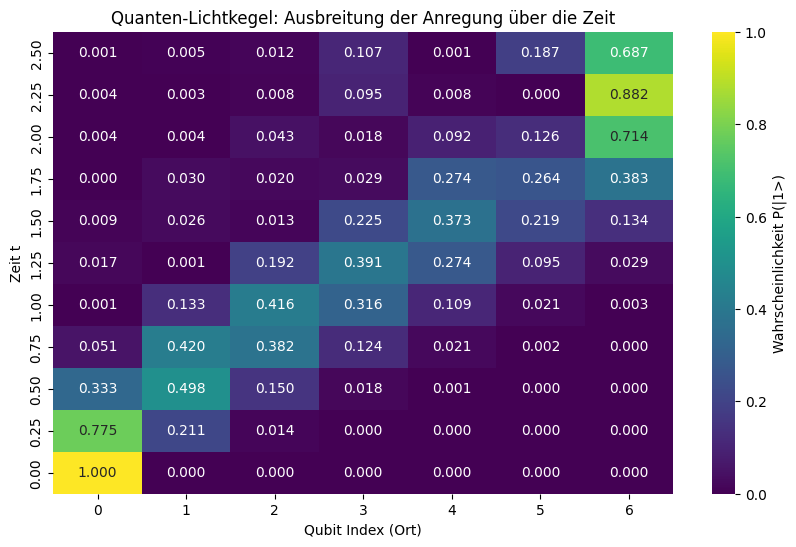

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

# Datenstruktur vorbereiten für die Visualisierung
# Wir extrahieren die Wahrscheinlichkeiten für den Zustand |1> für jedes Qubit zu jedem Zeitschritt
heatmap_data = []

for t in times:
    if t == 0:
        psi_t = psi_0
    else:
        psi_t = psi_0.evolve(HamiltonianGate(H_chain, time=t))

    # Wahrscheinlichkeit für Zustand |1> für jedes Qubit q extrahieren
    row = [psi_t.probabilities([q])[1] for q in range(n_qubits)]
    heatmap_data.append(row)

# In ein NumPy-Array konvertieren
heatmap_matrix = np.array(heatmap_data)

# Heatmap zeichnen
plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_matrix,
    annot=True,
    fmt=".3f",
    xticklabels=list(range(n_qubits)),
    yticklabels=[f"{t:.2f}" for t in times],
    cmap="viridis",
    cbar_kws={'label': 'Wahrscheinlichkeit P(|1>)'}
)

plt.title("Quanten-Lichtkegel: Ausbreitung der Anregung über die Zeit")
plt.xlabel("Qubit Index (Ort)")
plt.ylabel("Zeit t")
plt.gca().invert_yaxis() # Zeit läuft von unten nach oben
plt.show()

### Vergleich: Quanten-Dynamik ohne $Z$-Terme (Reines XX-Modell)

Wir erstellen nun einen neuen Hamilton-Operator `H_no_z`, der ausschließlich die Kopplungsterme ($XX + YY$) enthält, und vergleichen die Ausbreitung der Störung.

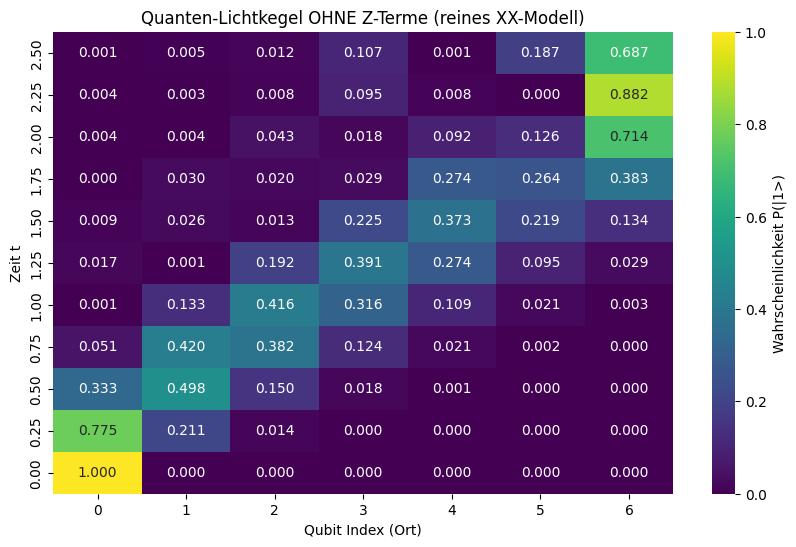

In [28]:
# Wir bauen die Pauli-Terme neu auf, aber NUR mit den XX- und YY-Kopplungen
pauli_terms_no_z = []
for i in range(n_qubits - 1):
    xx_str = ["I"] * n_qubits
    yy_str = ["I"] * n_qubits
    xx_str[n_qubits - 1 - i] = "X"
    xx_str[n_qubits - 2 - i] = "X"
    yy_str[n_qubits - 1 - i] = "Y"
    yy_str[n_qubits - 2 - i] = "Y"

    pauli_terms_no_z.append(("".join(xx_str), J))
    pauli_terms_no_z.append(("".join(yy_str), J))

H_no_z = SparsePauliOp.from_list(pauli_terms_no_z)

# Dynamik neu berechnen
heatmap_data_no_z = []
for t in times:
    if t == 0:
        psi_t = psi_0
    else:
        psi_t = psi_0.evolve(HamiltonianGate(H_no_z, time=t))

    row = [psi_t.probabilities([q])[1] for q in range(n_qubits)]
    heatmap_data_no_z.append(row)

heatmap_matrix_no_z = np.array(heatmap_data_no_z)

# Visualisierung
plt.figure(figsize=(10, 6))
sns.heatmap(
    heatmap_matrix_no_z,
    annot=True,
    fmt=".3f",
    xticklabels=list(range(n_qubits)),
    yticklabels=[f"{t:.2f}" for t in times],
    cmap="viridis",
    cbar_kws={'label': 'Wahrscheinlichkeit P(|1>)'}
)

plt.title("Quanten-Lichtkegel OHNE Z-Terme (reines XX-Modell)")
plt.xlabel("Qubit Index (Ort)")
plt.ylabel("Zeit t")
plt.gca().invert_yaxis()
plt.show()

### Warum sind die beiden Heatmaps exakt identisch?

Dass das Hinzufügen des homogenen Magnetfelds (die $Z$-Terme) absolut keinen Unterschied im Ergebnis macht, ist kein Fehler, sondern ein fundamentale quantenmechanisches Phänomen. Es lässt sich durch zwei Eigenschaften erklären:

#### 1. Erhaltung der Teilchenzahl ($U(1)$-Symmetrie)
Unser Anfangszustand $|1000000\rangle$ besitzt exakt **eine** lokale Anregung (ein einziges Qubit im Zustand $|1\rangle$, alle anderen im Grundzustand $|0\rangle$).
* Die Kopplungsterme $XX + YY$ wirken als Spin-Austausch-Operatoren. Sie können diese Anregung nur von einem Qubit auf ein benachbartes Qubit übertragen, aber sie können **keine neuen Anregungen erzeugen oder vernichten**.
* Die Gesamtanzahl der Anregungen im System ist eine Erhaltungsgröße und bleibt während der gesamten Dynamik exakt bei **eins**.

#### 2. Wirkung des homogenen Feldes als globale Phase
Die Pauli-$Z$-Matrix hat die Eigenwerte $+1$ (für $|0\rangle$) und $-1$ (für $|1\rangle$).

Wenn wir den Magnetfeld-Operator $H_Z = h \sum_{i} Z_i$ auf einen Zustand mit genau einer Anregung anwenden, erhalten wir immer denselben Gesamt-Eigenwert, unabhängig davon, auf welchem Qubit sich die Anregung gerade befindet:
$$\text{Gesamt-Eigenwert} = (N-1) \cdot (+1) + 1 \cdot (-1) = N - 2$$

Für unser System mit $N=7$ Qubits ist dieser Wert konstant $7 - 2 = 5$. Mathematisch bedeutet das:
$$\hat{H}_Z |\psi\rangle = (5 \cdot h) |\psi\rangle$$

In der quantenmechanischen Zeitentwicklung $e^{-i H t}$ führt dies dazu, dass der Hamiltonian mit $Z$-Termen dem gesamten Zustandsvektor lediglich eine **globale Phase** aufprägt:
$$|\psi_t\rangle_{\text{mit Z}} = e^{-i \cdot (5h) \cdot t} |\psi_t\rangle_{\text{ohne Z}}$$

#### 3. Globale Phasen sind nicht messbar
Bei der Berechnung der Aufenthaltswahrscheinlichkeiten $P(|1\rangle)$ für die Heatmap nehmen wir das Betragsquadrat des Zustands. Dabei fällt die komplexe Phase vollständig weg:
$$P(|1\rangle) = \left| e^{-i \cdot (5h) \cdot t} \cdot \psi_t \right|^2 = \left| e^{-i \cdot (5h) \cdot t} \right|^2 \cdot |\psi_t|^2 = 1 \cdot |\psi_t|^2$$

Daher zeigen beide Simulationen exakt dieselbe Dynamik. Ein Unterschied würde erst entstehen, wenn das Magnetfeld **inhomogen** wäre (z. B. wenn einzelne Qubits ein stärkeres Feld spüren würden als andere), da dies zu einer relativen Phasenverschiebung führen würde.